# Guardiã AI: EDA e comparação de modelos

Dataset **Maternal Health Risk** (UCI, CC BY 4.0): sinais vitais de gestantes e nível de risco (`low`, `mid`, `high risk`).

Este notebook usa as mesmas funções de `src/guardia/ml/train.py`, que é o código que gera o modelo da aplicação. Assim, o que se vê aqui é exatamente o que roda na app.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from guardia.ml.train import DATA_PATH, FEATURES, CLASSES, load_data, train_and_select, split, make_models
from guardia.ml.predict import LABELS_PT
raw = pd.read_csv(DATA_PATH)
raw.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


## 1. Variáveis

| Coluna | Significado | Unidade |
|---|---|---|
| Age | idade | anos |
| SystolicBP / DiastolicBP | pressão arterial sistólica / diastólica | mmHg |
| BS | glicemia | mmol/L |
| BodyTemp | temperatura corporal | °F |
| HeartRate | frequência cardíaca | bpm |
| RiskLevel | nível de risco (alvo) | low / mid / high |

In [2]:
raw.describe().round(1)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.0,1014.0,1014.0,1014.0,1014.0,1014.0
mean,29.9,113.2,76.5,8.7,98.7,74.3
std,13.5,18.4,13.9,3.3,1.4,8.1
min,10.0,70.0,49.0,6.0,98.0,7.0
25%,19.0,100.0,65.0,6.9,98.0,70.0
50%,26.0,120.0,80.0,7.5,98.0,76.0
75%,39.0,120.0,90.0,8.0,98.0,80.0
max,70.0,160.0,100.0,19.0,103.0,90.0


In [3]:
print('valores ausentes:', int(raw.isna().sum().sum()))
raw.RiskLevel.value_counts()

valores ausentes: 0


RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

## 2. Duplicatas: a decisão de preparação mais importante

Mais da metade das linhas são cópias exatas. Se elas ficarem, a mesma gestante cai no treino **e** no teste, e o modelo é avaliado em dados que já viu (vazamento). Por isso removemos as duplicatas **antes** do split.

In [4]:
dups = raw.duplicated().sum()
df = load_data()
print(f"linhas originais: {len(raw)} | duplicadas: {dups} | após deduplicação: {len(df)}")
df.RiskLevel.value_counts()

linhas originais: 1014 | duplicadas: 562 | após deduplicação: 452


RiskLevel
low risk     234
high risk    112
mid risk     106
Name: count, dtype: int64

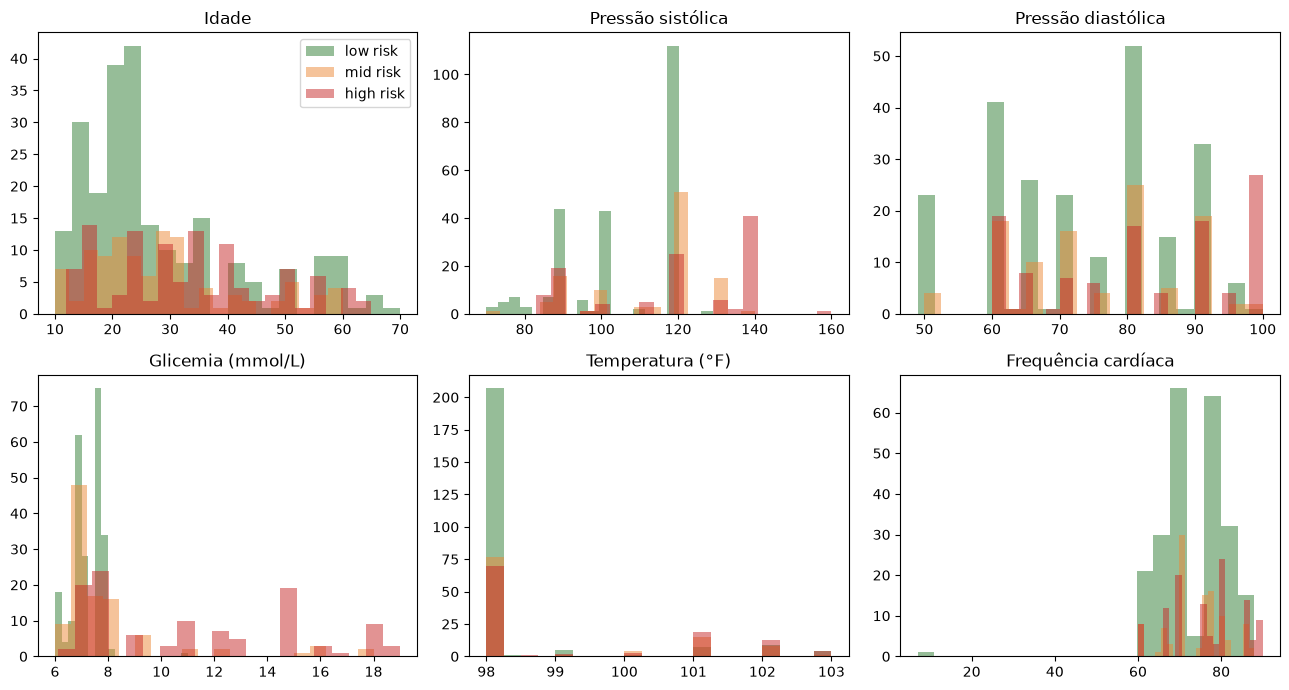

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.flat, FEATURES):
    for c, color in zip(CLASSES, ["#2e7d32", "#ed8936", "#c62828"]):
        ax.hist(df[df.RiskLevel == c][f], bins=20, alpha=.5, label=c, color=color)
    ax.set_title(LABELS_PT[f])
axes[0, 0].legend(); plt.tight_layout(); plt.show()

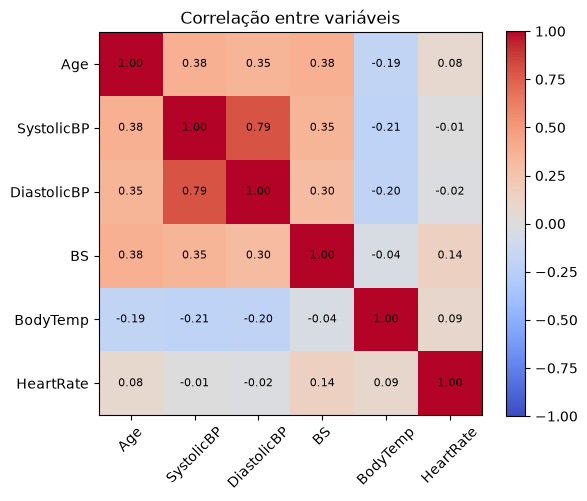

In [6]:
corr = df[FEATURES].corr()
plt.figure(figsize=(6, 5)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(6), FEATURES, rotation=45); plt.yticks(range(6), FEATURES)
for i in range(6):
    for j in range(6): plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlação entre variáveis"); plt.tight_layout(); plt.show()

Observações: glicemia (BS) e pressão sistólica separam bem a classe de alto risco. As pressões sistólica e diastólica são fortemente correlacionadas entre si. A classe `low risk` é a maior, mas o desbalanceamento é moderado.

## 3. Modelos e métrica central

Três modelos: **Regressão Logística** (baseline interpretável), **Random Forest** e **HistGradientBoosting**. Split estratificado 80/20 e validação cruzada estratificada de 5 folds no treino.

**Métrica central: recall da classe `high risk`.** Um falso negativo (gestante de alto risco classificada como baixo ou médio risco) pode atrasar um cuidado urgente. Um falso positivo gera uma avaliação a mais, custo bem menor. A seleção usa o maior recall de alto risco na validação cruzada, com desempate por F1 macro. A acurácia aparece só como referência.

In [7]:
import tempfile, pathlib
m = train_and_select(df, out_dir=pathlib.Path(tempfile.mkdtemp()))
tab = pd.DataFrame({n: {"recall_high (CV)": r["cv_recall_high"], "f1_macro (CV)": r["cv_f1_macro"],
                        **{f"{k} (teste)": v for k, v in r["test"].items() if k != "confusion_matrix"}}
                    for n, r in m["models"].items()}).T
print("vencedor:", m["best"]); tab.round(3)

vencedor: random_forest


,recall_high (CV),f1_macro (CV),recall_high (teste),precision_high (teste),f1_macro (teste),accuracy (teste)
logistic_regression,0.629,0.559,0.565,0.812,0.534,0.582
random_forest,0.753,0.589,0.696,0.889,0.573,0.582
hist_gradient_boosting,0.696,0.576,0.696,0.889,0.539,0.571


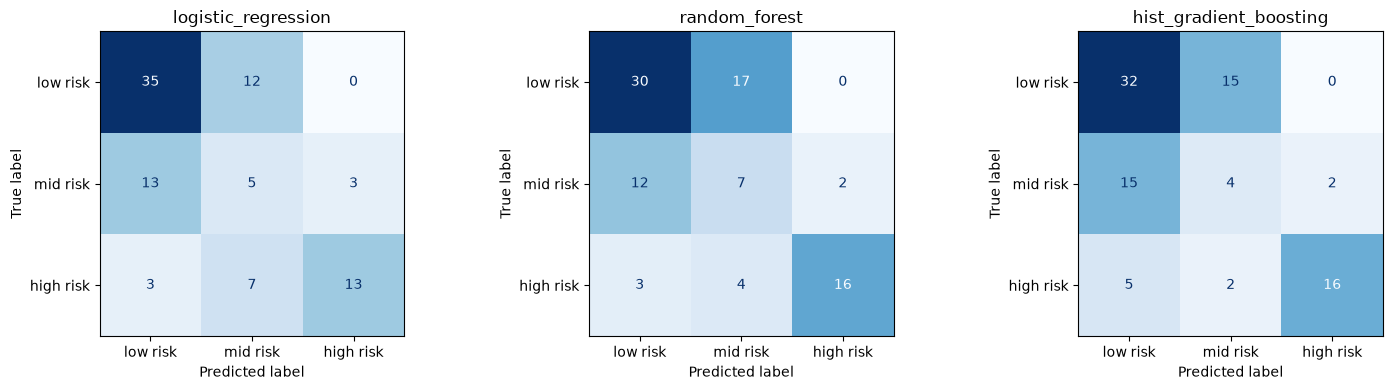

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, r) in zip(axes, m["models"].items()):
    ConfusionMatrixDisplay(np.array(r["test"]["confusion_matrix"]), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()

### Impacto dos erros

Na matriz de confusão, a linha `high risk` mostra quantas gestantes de alto risco o modelo deixou passar (falsos negativos). No conjunto de teste há só 23 casos de alto risco, então cada erro move o recall em ~4 pontos. Por isso a seleção usa a média da validação cruzada, que é mais estável, e não o teste.

**Por que os números são modestos?** Comparando com e sem deduplicação:

In [9]:
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(raw[FEATURES], raw.RiskLevel, test_size=.2, stratify=raw.RiskLevel, random_state=42)
rf = make_models()["random_forest"].fit(Xtr, ytr)
leak = recall_score(yte, rf.predict(Xte), labels=["high risk"], average="macro")
print(f"Random Forest SEM deduplicar: recall high = {leak:.3f}   (inflado: linhas repetidas no treino e no teste)")
print(f"Random Forest COM deduplicação: recall high = {m['models']['random_forest']['test']['recall_high']:.3f}   (estimativa honesta)")

Random Forest SEM deduplicar: recall high = 0.945   (inflado: linhas repetidas no treino e no teste)
Random Forest COM deduplicação: recall high = 0.696   (estimativa honesta)


Sem deduplicar, o número parece muito melhor, mas mede só a memorização de linhas repetidas. Reportamos a estimativa honesta e deixamos isso claro como limitação: com ~450 gestantes distintas, o modelo deve ser tratado como **indicativo de triagem**, nunca como decisão.

## 4. Explicabilidade (SHAP)

Global: quais variáveis mais empurram a predição para `high risk`.

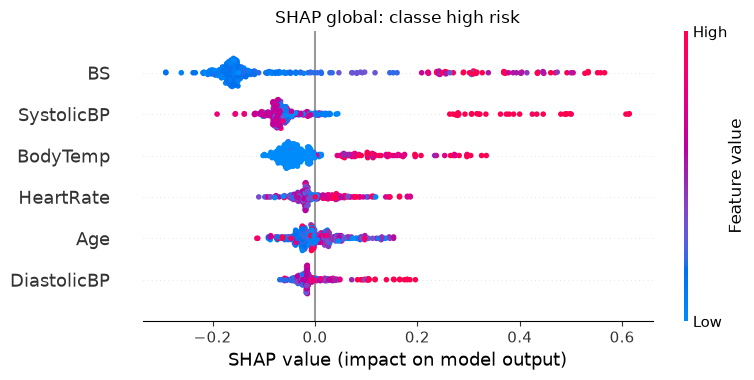

In [10]:
import shap
from guardia.ml.predict import _explainer, _bundle, explain
X_train, *_ = split(df)
exp = _explainer()(X_train)
hi = list(_bundle()["pipeline"].classes_).index("high risk")
shap.plots.beeswarm(exp[:, :, hi], show=False); plt.title("SHAP global: classe high risk"); plt.tight_layout(); plt.show()

Local: o que pesou para **um caso** (é isso que a app mostra para a profissional).

In [11]:
caso = {"Age": 35, "SystolicBP": 140, "DiastolicBP": 100, "BS": 15.0, "BodyTemp": 98.0, "HeartRate": 80}
pd.DataFrame(explain(caso)).assign(fator=lambda d: d.feature.map(LABELS_PT))[["fator", "value", "shap"]]

,fator,value,shap
0,Pressão sistólica,140.0,0.255703
1,Glicemia (mmol/L),15.0,0.239898
2,Pressão diastólica,100.0,0.088332
3,Idade,35.0,0.052698
4,Frequência cardíaca,80.0,0.038113
5,Temperatura (°F),98.0,-0.008635


## 5. Conclusões

- Random Forest teve o melhor recall de alto risco na validação cruzada e é o modelo da aplicação.
- Glicemia e pressão sistólica são os fatores mais influentes, o que é coerente com os protocolos de gestação de alto risco usados no RAG.
- Limitações: dataset pequeno, de uma única região (Bangladesh) e coletado por IoT. Não houve validação clínica no Brasil. Por isso o resultado é apoio à triagem, sob decisão da profissional.